# Burgers: ajuste del peso de la pérdida física en PCA k=8

Este notebook compara una PINN base con cuatro versiones PCA de ocho modos que ponderan de forma distinta el residuo PDE. Se mantienen las mismas diez semillas y cinco mil pasos por entrenamiento.


## Protocolo

- La pérdida PCA es `L = MSE_data + lambda_PDE * MSE_residual + MSE_initial`; se prueban `lambda_PDE = 1, 2, 5, 10`.
- Las variantes PCA inician con parámetros idénticos por semilla y comparten particiones, minibatches, puntos de colocación y observaciones iniciales.
- Se fija `k=8`, que tuvo el residuo más bajo entre los valores PCA del barrido anterior.
- Todas las redes autodiferencian `u_t`, `u_x` y `u_xx` con JAX durante el entrenamiento.
- Validación en checkpoints; prueba solo al final. El residuo informado se calcula con el mismo operador discreto en malla para todos los métodos.
- Se alterna el orden de ejecución por semilla. La compilación se reporta aparte; el tiempo PCA incluye el ajuste de su base.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
RUN_DIR = ROOT / "results" / "burgers" / "base_vs_pca" / "physics_weight_sweep_10_seeds_v1"
CONFIG = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
CHECKPOINTS = pd.read_csv(RUN_DIR / "checkpoint_metrics.csv")
TRAJECTORIES = pd.read_csv(RUN_DIR / "training_trajectories.csv")
print(f"JAX {RESULT['runtime']['jax']} | {RESULT['runtime']['device']}")
print(f"Semillas={len(CONFIG['seeds'])}; k={CONFIG['pca_components']}; pesos PDE={CONFIG['physics_weights']}")


JAX 0.12.0.1 | cpu:0
Semillas=10; k=8; pesos PDE=[1.0, 2.0, 5.0, 10.0]


## Métricas de prueba al checkpoint final (5000 pasos)


In [2]:
rows = []
for model, stats in RESULT["final_test_summary"].items():
    final_step = str(max(map(int, RESULT["checkpoint_summary"][model].keys())))
    detail = RESULT["checkpoint_summary"][model][final_step]
    rows.append({"Modelo": model, "lambda PDE": None if detail["lambda_pde"] is None else detail["lambda_pde"]["mean"],
        "RMSE": f"{stats['test_rmse']['mean']:.4f} ± {stats['test_rmse']['std']:.4f}",
        "Error relativo L2": f"{stats['test_relative_l2']['mean']:.4f} ± {stats['test_relative_l2']['std']:.4f}",
        "Residuo RMS Burgers": f"{stats['test_pde_residual_rms']['mean']:.4f} ± {stats['test_pde_residual_rms']['std']:.4f}",
        "Tiempo pipeline": f"{stats['elapsed_pipeline_seconds']['mean']:.2f} ± {stats['elapsed_pipeline_seconds']['std']:.2f} s"})
display(pd.DataFrame(rows))


Modelo,lambda PDE,RMSE,Error relativo L2,Residuo RMS Burgers,Tiempo pipeline
PINN base,—,0.1288 ± 0.0437,0.2088 ± 0.0644,0.7295 ± 0.2090,11.00 ± 0.34 s
"PCA k=8, lambda_PDE=1",1.0,0.2051 ± 0.0112,0.3343 ± 0.0096,0.2604 ± 0.0157,7.04 ± 0.17 s
"PCA k=8, lambda_PDE=2",2.0,0.2347 ± 0.0141,0.3826 ± 0.0135,0.2041 ± 0.0225,7.18 ± 0.37 s
"PCA k=8, lambda_PDE=5",5.0,0.2745 ± 0.0159,0.4475 ± 0.0157,0.1498 ± 0.0372,7.08 ± 0.23 s
"PCA k=8, lambda_PDE=10",10.0,0.3023 ± 0.0206,0.4926 ± 0.0219,0.1102 ± 0.0190,7.25 ± 0.65 s


## Diferencias pareadas frente a la PINN base


In [3]:
rows = []
for model, metrics in RESULT["paired_final_test_differences"].items():
    for key, label in [("test_relative_l2", "Error relativo L2"), ("test_pde_residual_rms", "Residuo RMS PDE"), ("elapsed_pipeline_seconds", "Tiempo de pipeline")]:
        value = metrics[key]
        rows.append({"Variante": model, "Métrica": label, "Diferencia media PCA − base": value["PCA_minus_base_mean"], "Semillas donde PCA fue menor": f"{value['PCA_better_count']}/{value['n']}"})
display(pd.DataFrame(rows))


Variante,Métrica,Diferencia media PCA − base,Semillas donde PCA fue menor
"PCA k=8, lambda_PDE=1",Error relativo L2,0.1255,1/10
"PCA k=8, lambda_PDE=1",Residuo RMS PDE,-0.4691,10/10
"PCA k=8, lambda_PDE=1",Tiempo de pipeline,-3.9587,10/10
"PCA k=8, lambda_PDE=2",Error relativo L2,0.1737,0/10
"PCA k=8, lambda_PDE=2",Residuo RMS PDE,-0.5254,10/10
"PCA k=8, lambda_PDE=2",Tiempo de pipeline,-3.8120,10/10
"PCA k=8, lambda_PDE=5",Error relativo L2,0.2387,0/10
"PCA k=8, lambda_PDE=5",Residuo RMS PDE,-0.5797,10/10
"PCA k=8, lambda_PDE=5",Tiempo de pipeline,-3.9148,10/10
"PCA k=8, lambda_PDE=10",Error relativo L2,0.2838,0/10


## Métricas de validación por checkpoint


In [4]:
rows = []
for model, checkpoints in RESULT["checkpoint_summary"].items():
    for step, stats in checkpoints.items():
        rows.append({"Modelo": model, "Paso": int(step), "RMSE validación": stats["validation_rmse"]["mean"], "Residuo RMS validación": stats["validation_pde_residual_rms"]["mean"], "Tiempo pipeline": stats["elapsed_pipeline_seconds"]["mean"]})
display(pd.DataFrame(rows).sort_values(["Paso", "Modelo"]))


Modelo,Paso,RMSE validación,Residuo RMS validación,Tiempo pipeline
PINN base,1000,0.2485,0.2437,2.20s
PINN base,2500,0.1561,0.4854,5.51s
PINN base,5000,0.1297,0.7283,11.00s
"PCA k=8, lambda_PDE=1",1000,0.2072,0.2696,1.39s
"PCA k=8, lambda_PDE=1",2500,0.2062,0.2486,3.49s
"PCA k=8, lambda_PDE=1",5000,0.2089,0.2475,7.04s
"PCA k=8, lambda_PDE=2",1000,0.2310,0.2262,1.44s
"PCA k=8, lambda_PDE=2",2500,0.2357,0.1888,3.63s
"PCA k=8, lambda_PDE=2",5000,0.2380,0.1940,7.18s
"PCA k=8, lambda_PDE=5",1000,0.2545,0.1939,1.43s


## Curvas por checkpoints


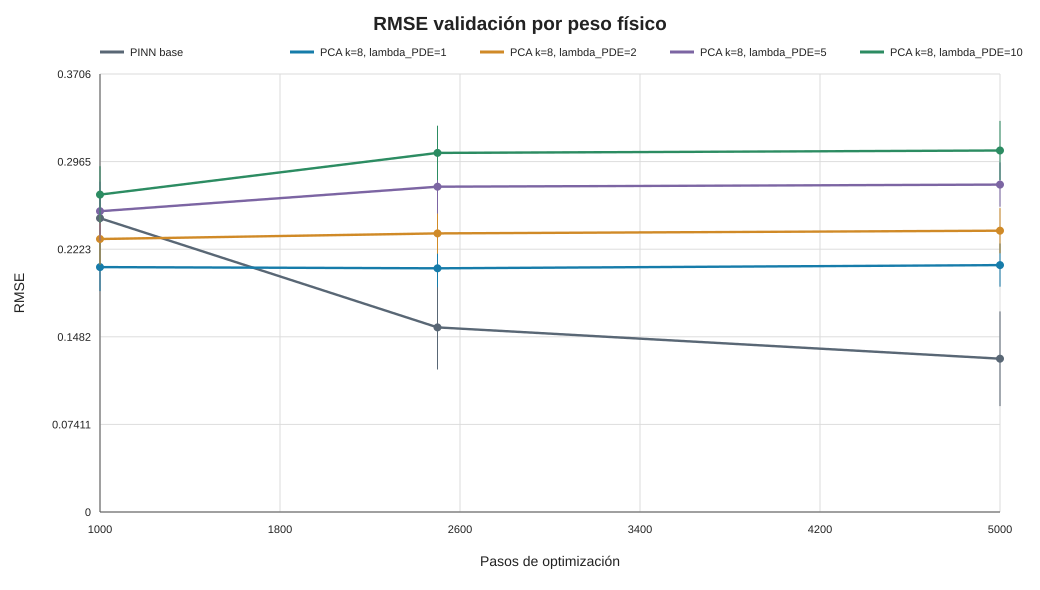

In [5]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))


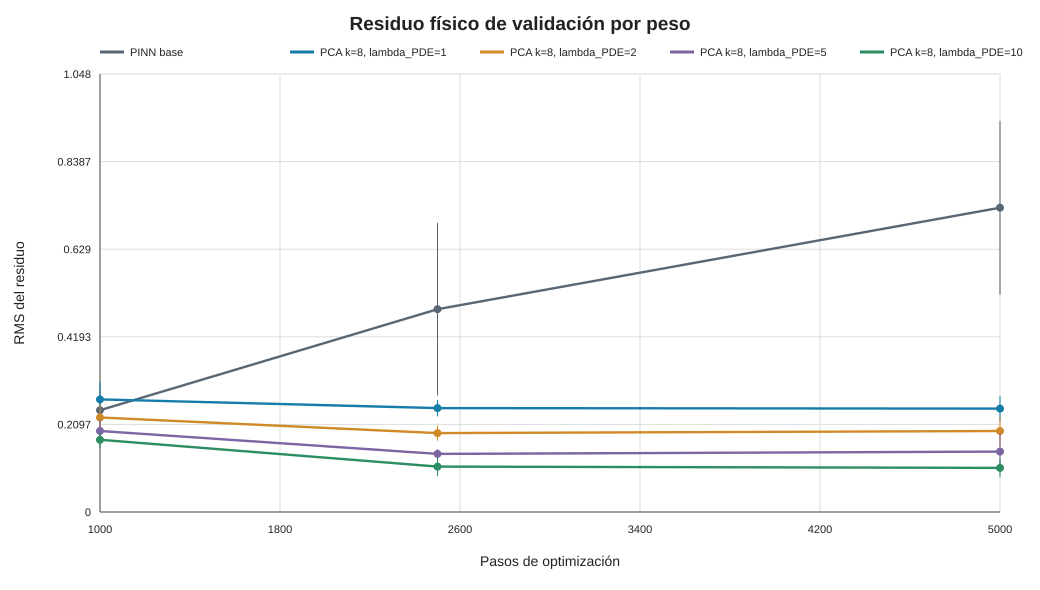

In [6]:
display(SVG(filename=str(RUN_DIR / "validation_residual_vs_steps.svg")))


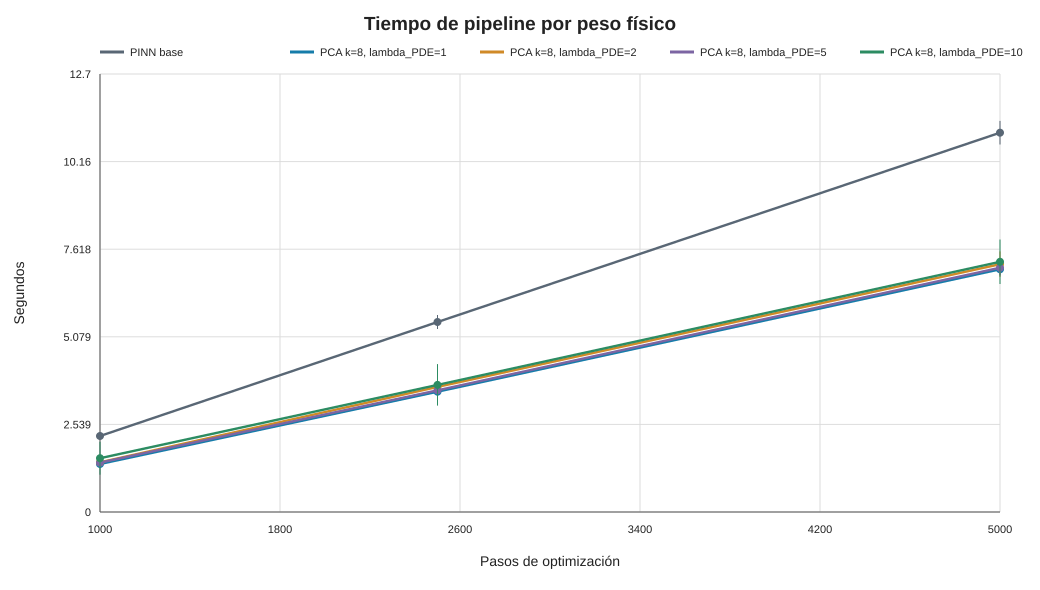

In [7]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))


## Comparación final


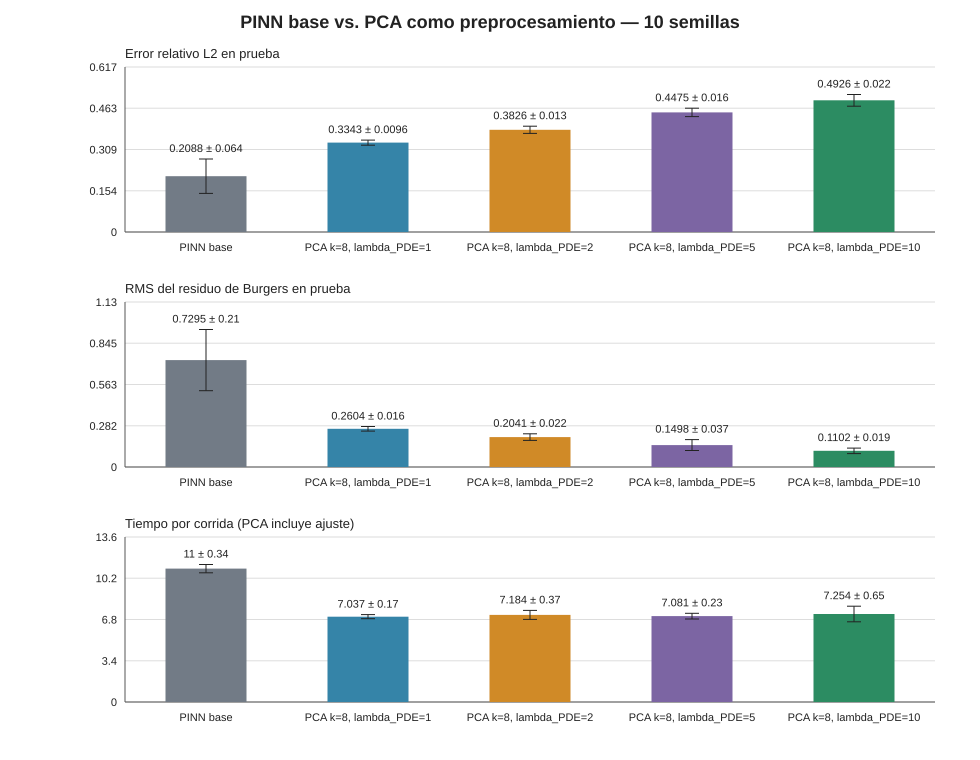

In [8]:
display(SVG(filename=str(RUN_DIR / "final_test_comparison.svg")))


## Lectura preliminar

Al subir `lambda_PDE` de 1 a 10, el residuo físico medio de prueba bajó de 0,260 a 0,110. El error relativo `L2` subió de 0,334 a 0,493. Así, reponderar la pérdida reduce el residuo, pero aleja la solución de referencia. El tiempo de las variantes PCA fue parecido (aprox. 7,0–7,3 s) y menor que el de la PINN base (aprox. 11,0 s) en este entorno.

Los objetivos de tiempo registran el primer cruce en evaluaciones cada 100 pasos y pueden ser transitorios. Este barrido es exploratorio: no define un peso universal. Para elegir un compromiso hay que fijar antes una regla conjunta de aceptación para error de solución y residuo físico, usando validación.


## Reproducir

La configuración está en `configs/burgers_physics_weight_sweep.json`; el ejecutor, en `scripts/run_physics_weight_sweep.py`. El notebook carga los resultados guardados. Ejecuta el script desde la raíz del repositorio para regenerar las 50 corridas.
